<a href="https://colab.research.google.com/github/ReversePI78/-DevelRocket-AI-game-review-analysis/blob/main/21%EC%B0%A8%EC%8B%9C_%EB%8B%A4%EC%B0%A8%EC%9B%90%ED%86%B5%ED%95%A9%EB%B6%84%EC%84%9D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 21차시: 다차원 분석 통합 (프로젝트)

**학습 목표**
- 감성, Aspect, 키워드를 하나의 프롬프트로 통합할 수 있다
- 구조화된 JSON 결과를 파싱하고 활용할 수 있다
- 통합 파이프라인으로 여러 리뷰를 자동 분석할 수 있다

---

## 1. 배경: 왜 통합이 필요한가?

### 지금까지 배운 것들

| 차시 | 기법 | 결과 |
|------|------|------|
| 17-18차시 | 감성 분석 | `POSITIVE / NEGATIVE / MIXED` |
| 19차시 | Aspect 기반 감성 | `{graphics: POSITIVE, ...}` |
| 20차시 | 키워드 + 토픽 | `[{word: "bugs", topic: "technical"}]` |

### 문제점: 분리된 API 호출

```
리뷰 1개 분석하려면...

API 호출 #1 → 감성 분석
API 호출 #2 → Aspect 분석
API 호출 #3 → 키워드 추출

= 3번 호출, 3배 비용, 3배 시간!
```

### 해결책: 통합 프롬프트

```
리뷰 1개 → 통합 분석 → 감성 + Aspect + 키워드 + 요약

= 1번 호출로 끝!
```

이번 프로젝트에서 **하나의 프롬프트로 모든 분석을 수행**하는 통합 파이프라인을 만듭니다.

---

## 2. 목표: 무엇을 만들 것인가?

### 최종 산출물

**입력**: 리뷰 텍스트 1개

**출력**: 다차원 분석 결과 (JSON)

```json
{
  "sentiment": "MIXED",
  "aspects": {
    "graphics": "POSITIVE",
    "performance": "NEGATIVE",
    "story": "NOT_MENTIONED"
  },
  "keywords": [
    {"word": "visuals", "topic": "content"},
    {"word": "crashes", "topic": "technical"}
  ],
  "summary": "그래픽은 훌륭하지만 잦은 크래시가 문제"
}
```

### 구체적 목표

1. **통합 분석 함수** 만들기
2. **샘플 리뷰 10개** 자동 분석
3. **결과 집계** (감성 분포, 토픽 분포)
4. **CSV로 저장**

---

## 3. 설계: 어떻게 접근할 것인가?

코드 작성 전에 **한글로 순서를 정리**해봅시다.

### 수도 코드 (Pseudocode)

```
1. 준비
   - API 키 불러오기
   - 클라이언트 설정하기
   - 사용할 모델 지정하기 (한 곳에서 관리)

2. 유틸리티 함수 정의
   - JSON 응답 정제 함수 (마크다운 코드블록 제거 등)
   - LLM 호출 헬퍼 함수

3. 통합 분석 프롬프트 설계
   - 역할: 게임 리뷰 분석 전문가
   - 분석 항목 4가지 정의
   - Few-shot 예시 제공
   - JSON 출력 형식 지정

4. 통합 분석 함수 구현
   - 리뷰 입력 받기
   - LLM API 호출
   - JSON 파싱 (정제 함수 활용)
   - 결과 반환

5. 반복 처리 및 집계
```

이제 이 순서대로 코드를 작성해봅시다!

---

## 4. 구현: 단계별 코드 작성

### 4-1. 준비 단계

> **(실습에서는 무료로 빠르게 쓸 수 있는 Groq의 gpt-oss-20b 모델을 사용합니다.)**

In [3]:
# =============================================================================
# 라이브러리 설치
# =============================================================================

!pip install openai -q
print("설치 완료!")

설치 완료!


In [4]:
# =============================================================================
# 설정: API 키, 클라이언트, 모델
# =============================================================================
# 모델을 여기서 한 번만 지정하면 전체 노트북에서 동일하게 사용됩니다.
# 모델을 변경하고 싶으면 이 셀의 MODEL 값만 수정하세요.
# =============================================================================

from google.colab import userdata
from openai import OpenAI

# --- 설정값 (필요시 여기만 수정) ---
MODEL = "openai/gpt-oss-20b"  # 사용할 LLM 모델
API_BASE_URL = "https://api.groq.com/openai/v1"  # API 엔드포인트

# --- API 키 로드 ---
api_key = userdata.get('GROQ_API_KEY')

# --- 클라이언트 초기화 ---
client = OpenAI(
    base_url=API_BASE_URL,
    api_key=api_key
)

print(f"키 확인: {'있음' if api_key else '없음'} (길이 {len(api_key or '')}자)")  # 키 일부도 출력하지 않음
print(f"모델: {MODEL}")
print("클라이언트 준비 완료!")

키 확인: 있음 (길이 56자)
모델: openai/gpt-oss-20b
클라이언트 준비 완료!


### 4-2. 유틸리티 함수 정의

LLM 응답을 안전하게 처리하기 위한 헬퍼 함수들을 먼저 정의합니다.

In [5]:
# =============================================================================
# 유틸리티 함수: JSON 응답 정제
# =============================================================================
# LLM 모델에 따라 JSON 응답 형식이 다를 수 있습니다:
# - 일부 모델: 순수 JSON만 반환
# - 일부 모델: ```json ... ``` 마크다운 코드블록으로 감싸서 반환
# - 일부 모델: 앞뒤에 설명 텍스트가 붙어서 반환
#
# 이 함수는 다양한 형식의 응답에서 순수 JSON 문자열만 추출합니다.
# =============================================================================

import re

def clean_json_response(response_text):
    """
    LLM 응답에서 순수 JSON 문자열만 추출합니다.

    처리하는 케이스:
    1. ```json ... ``` 코드블록
    2. ``` ... ``` 일반 코드블록
    3. 앞뒤 공백/줄바꿈
    4. JSON 앞뒤의 불필요한 텍스트

    Args:
        response_text: LLM의 원본 응답 텍스트

    Returns:
        정제된 JSON 문자열
    """
    text = response_text.strip()

    # 케이스 1: ```json ... ``` 코드블록 처리
    if "```json" in text:
        # ```json과 ``` 사이의 내용 추출
        match = re.search(r'```json\s*([\s\S]*?)\s*```', text)
        if match:
            return match.group(1).strip()

    # 케이스 2: ``` ... ``` 일반 코드블록 처리
    if "```" in text:
        match = re.search(r'```\s*([\s\S]*?)\s*```', text)
        if match:
            return match.group(1).strip()

    # 케이스 3: JSON 객체/배열 직접 추출 시도
    # { 로 시작해서 } 로 끝나는 부분, 또는 [ 로 시작해서 ] 로 끝나는 부분
    json_match = re.search(r'(\{[\s\S]*\}|\[[\s\S]*\])', text)
    if json_match:
        return json_match.group(1).strip()

    # 매칭 실패 시 원본 반환 (이후 파싱에서 에러 처리)
    return text


# --- 테스트 ---
test_cases = [
    # 케이스 1: json 코드블록
    '```json\n{"sentiment": "POSITIVE"}\n```',
    # 케이스 2: 일반 코드블록
    '```\n{"sentiment": "NEGATIVE"}\n```',
    # 케이스 3: 앞뒤 텍스트
    'Here is the result:\n{"sentiment": "MIXED"}\nHope this helps!',
    # 케이스 4: 순수 JSON
    '{"sentiment": "POSITIVE"}'
]

print("=== clean_json_response 테스트 ===")
for i, case in enumerate(test_cases, 1):
    cleaned = clean_json_response(case)
    print(f"케이스 {i}: {cleaned}")

=== clean_json_response 테스트 ===
케이스 1: {"sentiment": "POSITIVE"}
케이스 2: {"sentiment": "NEGATIVE"}
케이스 3: {"sentiment": "MIXED"}
케이스 4: {"sentiment": "POSITIVE"}


In [6]:
# =============================================================================
# 유틸리티 함수: LLM 호출 헬퍼
# =============================================================================
# 모델 지정을 중앙화하여 매번 model 파라미터를 적지 않아도 됩니다.
# =============================================================================

def call_llm(system_prompt, user_message):
    """
    LLM API를 호출하고 응답 텍스트를 반환합니다.

    Args:
        system_prompt: 시스템 프롬프트 (역할, 규칙 등)
        user_message: 사용자 메시지 (분석할 내용)

    Returns:
        LLM 응답 텍스트
    """
    response = client.chat.completions.create(
        model=MODEL,  # 상단에서 정의한 모델 사용
        messages=[
            {"role": "system", "content": system_prompt},
            {"role": "user", "content": user_message}
        ],
        max_tokens=1024
    )
    return response.choices[0].message.content


def call_llm_json(system_prompt, user_message):
    """
    LLM API를 호출하고 JSON으로 파싱된 결과를 반환합니다.

    Args:
        system_prompt: 시스템 프롬프트
        user_message: 사용자 메시지

    Returns:
        dict: 파싱된 JSON 객체

    Raises:
        json.JSONDecodeError: JSON 파싱 실패 시
    """
    import json

    raw_response = call_llm(system_prompt, user_message)
    cleaned = clean_json_response(raw_response)
    return json.loads(cleaned)


print("LLM 호출 헬퍼 함수 정의 완료!")
print(f"사용 모델: {MODEL}")

LLM 호출 헬퍼 함수 정의 완료!
사용 모델: openai/gpt-oss-20b


### 4-3. 통합 분석 프롬프트 설계

핵심은 **하나의 프롬프트에 4가지 분석 항목을 명확하게 정의**하는 것입니다.

In [7]:
# =============================================================================
# 통합 분석 시스템 프롬프트
# =============================================================================
# 4가지 분석 항목을 하나의 프롬프트로 통합:
# 1. sentiment: 전체 감성
# 2. aspects: Aspect별 감성
# 3. keywords: 키워드 + 토픽
# 4. summary: 한줄 요약
# =============================================================================

SYSTEM_PROMPT = """너는 게임 리뷰 분석 전문가야.
리뷰를 분석해서 다음 4가지 정보를 JSON 형식으로 추출해.

### 분석 항목 ###

1. sentiment (전체 감성)
   - POSITIVE: 전반적으로 긍정적
   - NEGATIVE: 전반적으로 부정적
   - MIXED: 긍정과 부정이 섞임

2. aspects (항목별 감성)
   6가지 항목에 대해 각각 분석:
   - graphics: 그래픽, 비주얼, 아트 관련
   - gameplay: 게임플레이, 조작, 재미 관련
   - story: 스토리, 캐릭터, 세계관 관련
   - performance: 성능, 최적화, 프레임 관련
   - value: 가격, 가성비, 플레이타임 관련
   - multiplayer: 멀티플레이, 서버, 매칭 관련

   각 항목의 값:
   - POSITIVE: 긍정적으로 언급됨
   - NEGATIVE: 부정적으로 언급됨
   - NEUTRAL: 중립적으로 언급됨
   - NOT_MENTIONED: 언급되지 않음

3. keywords (핵심 키워드 + 토픽)
   - 최대 5개까지
   - 토픽: technical, content, value, community, other 중 하나

4. summary (한줄 요약)
   - 한국어로 1-2문장
   - 핵심 내용만 간결하게

### 예시 ###
리뷰: "Stunning graphics and an engaging story, but the game crashes every hour. Not worth full price."

{
  "sentiment": "MIXED",
  "aspects": {
    "graphics": "POSITIVE",
    "gameplay": "NOT_MENTIONED",
    "story": "POSITIVE",
    "performance": "NEGATIVE",
    "value": "NEGATIVE",
    "multiplayer": "NOT_MENTIONED"
  },
  "keywords": [
    {"word": "graphics", "topic": "content"},
    {"word": "story", "topic": "content"},
    {"word": "crashes", "topic": "technical"},
    {"word": "price", "topic": "value"}
  ],
  "summary": "그래픽과 스토리는 훌륭하지만 잦은 크래시와 높은 가격이 문제"
}
### 예시 끝 ###

반드시 위 JSON 구조를 정확히 따라서 답해. JSON만 출력하고 다른 텍스트는 포함하지 마."""

print("시스템 프롬프트 정의 완료!")
print(f"프롬프트 길이: {len(SYSTEM_PROMPT)}자")

시스템 프롬프트 정의 완료!
프롬프트 길이: 1315자


### 4-4. 통합 분석 함수 구현

In [8]:
# =============================================================================
# 통합 분석 함수
# =============================================================================
# 앞서 정의한 유틸리티 함수들을 활용하여 깔끔하게 구현합니다.
# - call_llm_json(): 모델 지정 + JSON 파싱 자동 처리
# - clean_json_response(): 내부에서 자동 호출됨
# =============================================================================

import json

def unified_analyze(review):
    """
    리뷰 하나를 통합 분석합니다 (감성 + Aspect + 키워드 + 요약).

    Args:
        review: 분석할 리뷰 텍스트

    Returns:
        dict: {
            "success": bool,  # 파싱 성공 여부
            "data": dict,     # 분석 결과 또는 에러 정보
            "raw_response": str  # (실패 시) 원본 응답
        }
    """
    try:
        # LLM 호출 + JSON 파싱 (헬퍼 함수 사용)
        parsed = call_llm_json(SYSTEM_PROMPT, f"리뷰: {review}")
        return {
            "success": True,
            "data": parsed
        }

    except json.JSONDecodeError as e:
        # JSON 파싱 실패 시 기본값 반환
        return {
            "success": False,
            "data": {
                "sentiment": "PARSE_ERROR",
                "aspects": {},
                "keywords": [],
                "summary": f"파싱 실패: {str(e)[:50]}"
            }
        }
    except Exception as e:
        # 기타 에러 (API 오류 등)
        return {
            "success": False,
            "data": {
                "sentiment": "API_ERROR",
                "aspects": {},
                "keywords": [],
                "summary": f"에러: {str(e)[:50]}"
            }
        }

print("통합 분석 함수 정의 완료!")

통합 분석 함수 정의 완료!


In [9]:
# =============================================================================
# 함수 테스트
# =============================================================================

test_review = """Beautiful visuals and an amazing soundtrack make this game a treat.
However, constant crashes and server issues ruin the multiplayer experience.
Story mode is short but engaging. Not worth $60, wait for a sale."""

print("=== 테스트 리뷰 ===")
print(test_review)
print()

result = unified_analyze(test_review)

print("=== 분석 결과 ===")
if result["success"]:
    data = result["data"]
    print(f"✅ 파싱 성공!")
    print(f"\n감성: {data.get('sentiment')}")
    print(f"\nAspect별 감성:")
    for aspect, sent in data.get('aspects', {}).items():
        print(f"  - {aspect}: {sent}")
    print(f"\n키워드:")
    for kw in data.get('keywords', []):
        print(f"  - {kw.get('word')} [{kw.get('topic')}]")
    print(f"\n요약: {data.get('summary')}")
else:
    print(f"❌ 파싱 실패")
    print(f"에러: {result['data'].get('summary')}")

=== 테스트 리뷰 ===
Beautiful visuals and an amazing soundtrack make this game a treat.
However, constant crashes and server issues ruin the multiplayer experience.
Story mode is short but engaging. Not worth $60, wait for a sale.

=== 분석 결과 ===
❌ 파싱 실패
에러: 파싱 실패: Expecting ',' delimiter: line 12 column 44 (char 2


### 4-5. 샘플 데이터 준비

In [10]:
# =============================================================================
# 샘플 리뷰 데이터
# =============================================================================

sample_reviews = [
    # 긍정적 리뷰 (3개)
    "Absolutely stunning graphics and immersive story. The gameplay loop is addictive. Best RPG of the year!",
    "10/10 game. Smooth performance, beautiful world, and the multiplayer is so much fun with friends.",
    "Worth every penny. 200 hours in and still finding new things. The developers really care about this game.",

    # 부정적 리뷰 (3개)
    "Terrible optimization. Game crashes every 30 minutes. Do not buy until they fix it.",
    "Boring gameplay and forgettable story. Graphics are outdated. Waste of $60.",
    "Multiplayer is completely broken. Servers are always down. Refunded after 2 hours.",

    # 혼합 리뷰 (4개)
    "Amazing graphics and art direction, but the story is generic and short. Good on sale.",
    "Fun gameplay mechanics but ruined by constant bugs and crashes. Potential is there.",
    "Great single player campaign but multiplayer matchmaking is terrible. Mixed feelings.",
    "Beautiful world and characters but performance issues make it unplayable at times. Wait for patches."
]

print(f"샘플 리뷰 {len(sample_reviews)}개 준비 완료!")

샘플 리뷰 10개 준비 완료!


### 4-6. 반복 처리

In [11]:
# =============================================================================
# 전체 리뷰 자동 분석
# =============================================================================

import time

results = []

print("=== 통합 분석 시작 ===")
print(f"모델: {MODEL}")
print(f"총 {len(sample_reviews)}개 리뷰를 분석합니다.")
print()

for i, review in enumerate(sample_reviews, 1):
    print(f"[{i}/{len(sample_reviews)}] 분석 중...")

    analysis = unified_analyze(review)

    if analysis["success"]:
        data = analysis["data"]
        results.append({
            "review": review,
            "sentiment": data.get("sentiment", "UNKNOWN"),
            "aspects": data.get("aspects", {}),
            "keywords": data.get("keywords", []),
            "summary": data.get("summary", "")
        })
        print(f"    → {data.get('sentiment', 'UNKNOWN')}")
    else:
        results.append({
            "review": review,
            "sentiment": "PARSE_ERROR",
            "aspects": {},
            "keywords": [],
            "summary": "파싱 실패"
        })
        print(f"    → 파싱 실패")

    # API 부하 방지
    if i < len(sample_reviews):
        time.sleep(1)

print()
print(f"=== 완료! {len(results)}개 리뷰 분석 완료 ===")

=== 통합 분석 시작 ===
모델: openai/gpt-oss-20b
총 10개 리뷰를 분석합니다.

[1/10] 분석 중...
    → POSITIVE
[2/10] 분석 중...
    → POSITIVE
[3/10] 분석 중...
    → POSITIVE
[4/10] 분석 중...
    → NEGATIVE
[5/10] 분석 중...
    → NEGATIVE
[6/10] 분석 중...
    → NEGATIVE
[7/10] 분석 중...
    → POSITIVE
[8/10] 분석 중...
    → 파싱 실패
[9/10] 분석 중...
    → MIXED
[10/10] 분석 중...
    → MIXED

=== 완료! 10개 리뷰 분석 완료 ===


### 4-7. 결과 확인 및 집계

In [12]:
# 상세 결과 출력 (처음 3개)

print("=== 상세 분석 결과 (처음 3개) ===")
print()

for i, r in enumerate(results[:3], 1):
    print(f"--- 리뷰 {i} ---")
    print(f"원본: {r['review'][:70]}...")
    print(f"감성: {r['sentiment']}")

    mentioned = {k: v for k, v in r['aspects'].items() if v != "NOT_MENTIONED"}
    if mentioned:
        print(f"Aspects: {mentioned}")

    if r['keywords']:
        kw_list = [f"{k['word']}[{k['topic']}]" for k in r['keywords'][:3]]
        print(f"키워드: {', '.join(kw_list)}")

    print(f"요약: {r['summary']}")
    print()

=== 상세 분석 결과 (처음 3개) ===

--- 리뷰 1 ---
원본: Absolutely stunning graphics and immersive story. The gameplay loop is...
감성: POSITIVE
Aspects: {'graphics': 'POSITIVE', 'gameplay': 'POSITIVE', 'story': 'POSITIVE'}
키워드: graphics[content], story[content], gameplay[content]
요약: 그래픽, 스토리, 게임플레이가 모두 뛰어나며 올해 최고의 RPG로 평가된다.

--- 리뷰 2 ---
원본: 10/10 game. Smooth performance, beautiful world, and the multiplayer i...
감성: POSITIVE
Aspects: {'graphics': 'POSITIVE', 'performance': 'POSITIVE', 'multiplayer': 'POSITIVE'}
키워드: performance[technical], world[content], multiplayer[community]
요약: 스무스한 퍼포먼스와 아름다운 세계, 즐거운 멀티플레이가 돋보이는 10/10 게임.

--- 리뷰 3 ---
원본: Worth every penny. 200 hours in and still finding new things. The deve...
감성: POSITIVE
Aspects: {'gameplay': 'POSITIVE', 'value': 'POSITIVE'}
키워드: worth every penny[value], 200 hours[content], new things[content]
요약: 가격 대비 가성비가 뛰어나고, 200시간 넘게 플레이해도 새로운 것을 발견하며 개발자들이 진심으로 돌봐주는 게임입니다.



In [13]:
from collections import Counter

# 감성 분포
sentiment_counts = Counter(r["sentiment"] for r in results)

print("=== 감성 분포 ===")
print()
for sentiment, count in sentiment_counts.most_common():
    pct = count / len(results) * 100
    bar = "█" * int(pct / 5)
    print(f"{sentiment:15} {count}개 ({pct:5.1f}%) {bar}")

=== 감성 분포 ===

POSITIVE        4개 ( 40.0%) ████████
NEGATIVE        3개 ( 30.0%) ██████
MIXED           2개 ( 20.0%) ████
PARSE_ERROR     1개 ( 10.0%) ██


In [14]:
# Aspect별 감성 분포

aspect_stats = {
    "graphics": {"POSITIVE": 0, "NEGATIVE": 0, "NEUTRAL": 0, "NOT_MENTIONED": 0},
    "gameplay": {"POSITIVE": 0, "NEGATIVE": 0, "NEUTRAL": 0, "NOT_MENTIONED": 0},
    "story": {"POSITIVE": 0, "NEGATIVE": 0, "NEUTRAL": 0, "NOT_MENTIONED": 0},
    "performance": {"POSITIVE": 0, "NEGATIVE": 0, "NEUTRAL": 0, "NOT_MENTIONED": 0},
    "value": {"POSITIVE": 0, "NEGATIVE": 0, "NEUTRAL": 0, "NOT_MENTIONED": 0},
    "multiplayer": {"POSITIVE": 0, "NEGATIVE": 0, "NEUTRAL": 0, "NOT_MENTIONED": 0}
}

for r in results:
    for aspect, sent in r["aspects"].items():
        if aspect in aspect_stats and sent in aspect_stats[aspect]:
            aspect_stats[aspect][sent] += 1

print("=== Aspect별 감성 분포 ===")
print()
print(f"{'Aspect':12} {'긍정':>6} {'부정':>6} {'중립':>6} {'미언급':>6}")
print("-" * 42)

for aspect, stats in aspect_stats.items():
    print(f"{aspect:12} {stats['POSITIVE']:>6} {stats['NEGATIVE']:>6} {stats['NEUTRAL']:>6} {stats['NOT_MENTIONED']:>6}")

=== Aspect별 감성 분포 ===

Aspect           긍정     부정     중립    미언급
------------------------------------------
graphics          4      1      0      4
gameplay          3      1      0      5
story             2      2      0      5
performance       1      2      0      6
value             2      1      0      6
multiplayer       1      2      0      6


In [15]:
# 토픽별 키워드 분포

all_keywords = []
for r in results:
    all_keywords.extend(r["keywords"])

topic_counts = Counter(kw.get("topic", "other") for kw in all_keywords)
word_counts = Counter(kw.get("word", "").lower() for kw in all_keywords)

print("=== 토픽별 분포 ===")
total_kw = len(all_keywords)
for topic, count in topic_counts.most_common():
    pct = count / total_kw * 100 if total_kw > 0 else 0
    bar = "█" * int(pct / 5)
    print(f"{topic:12} {count:2}개 ({pct:5.1f}%) {bar}")

print()
print("=== 키워드 빈도 Top 10 ===")
for rank, (word, count) in enumerate(word_counts.most_common(10), 1):
    bar = "█" * count
    print(f"{rank:2}. {word:15} {count}회 {bar}")

=== 토픽별 분포 ===
content      16개 ( 43.2%) ████████
technical    11개 ( 29.7%) █████
community     5개 ( 13.5%) ██
value         5개 ( 13.5%) ██

=== 키워드 빈도 Top 10 ===
 1. graphics        3회 ███
 2. story           3회 ███
 3. multiplayer     3회 ███
 4. gameplay        2회 ██
 5. performance     2회 ██
 6. immersive       1회 █
 7. rpg             1회 █
 8. world           1회 █
 9. smooth          1회 █
10. worth every penny 1회 █


### 4-8. 인사이트 도출

In [16]:
print("=== 분석 인사이트 ===")
print()

# 1. 전체 감성 경향
positive_rate = sentiment_counts.get("POSITIVE", 0) / len(results) * 100
negative_rate = sentiment_counts.get("NEGATIVE", 0) / len(results) * 100
mixed_rate = sentiment_counts.get("MIXED", 0) / len(results) * 100

print(f"[감성 경향]")
if positive_rate > negative_rate:
    print(f"  → 긍정 리뷰({positive_rate:.0f}%)가 부정 리뷰({negative_rate:.0f}%)보다 많습니다.")
elif negative_rate > positive_rate:
    print(f"  → 부정 리뷰({negative_rate:.0f}%)가 긍정 리뷰({positive_rate:.0f}%)보다 많습니다.")
else:
    print(f"  → 긍정과 부정 리뷰가 비슷한 비율입니다.")

print()

# 2. 문제 Aspect 식별
print(f"[문제 영역 식별]")
problem_aspects = []
for aspect, stats in aspect_stats.items():
    if stats["NEGATIVE"] > stats["POSITIVE"]:
        problem_aspects.append(aspect)

if problem_aspects:
    print(f"  → 부정 비율이 높은 영역: {', '.join(problem_aspects)}")
else:
    print(f"  → 모든 영역에서 긍정 비율이 높거나 비슷합니다.")

print()

# 3. 주요 토픽
print(f"[주요 관심사]")
if topic_counts:
    top_topic, top_count = topic_counts.most_common(1)[0]
    top_pct = top_count / total_kw * 100 if total_kw > 0 else 0
    print(f"  → '{top_topic}' 토픽이 전체의 {top_pct:.0f}%로 가장 많이 언급됨")

=== 분석 인사이트 ===

[감성 경향]
  → 긍정 리뷰(40%)가 부정 리뷰(30%)보다 많습니다.

[문제 영역 식별]
  → 부정 비율이 높은 영역: performance, multiplayer

[주요 관심사]
  → 'content' 토픽이 전체의 43%로 가장 많이 언급됨


### 4-9. CSV로 저장

In [17]:
import pandas as pd

# 결과를 DataFrame으로 변환 (평탄화)
flat_results = []

for r in results:
    row = {
        "review": r["review"],
        "sentiment": r["sentiment"],
        "summary": r["summary"]
    }

    for aspect in ["graphics", "gameplay", "story", "performance", "value", "multiplayer"]:
        row[f"aspect_{aspect}"] = r["aspects"].get(aspect, "NOT_MENTIONED")

    row["keywords"] = ", ".join([kw.get("word", "") for kw in r["keywords"]])
    row["topics"] = ", ".join([kw.get("topic", "") for kw in r["keywords"]])

    flat_results.append(row)

df = pd.DataFrame(flat_results)

output_filename = "unified_analysis_results.csv"
df.to_csv(output_filename, index=False, encoding="utf-8-sig")

print(f"결과가 '{output_filename}'에 저장되었습니다!")
print(f"총 {len(df)}개 행, {len(df.columns)}개 열")

결과가 'unified_analysis_results.csv'에 저장되었습니다!
총 10개 행, 11개 열


In [18]:
df.head(3)

,review,sentiment,summary,aspect_graphics,aspect_gameplay,aspect_story,aspect_performance,aspect_value,aspect_multiplayer,keywords,topics
0,Absolutely stunning graphics and immersive sto...,POSITIVE,"그래픽, 스토리, 게임플레이가 모두 뛰어나며 올해 최고의 RPG로 평가된다.",POSITIVE,POSITIVE,POSITIVE,NOT_MENTIONED,NOT_MENTIONED,NOT_MENTIONED,"graphics, story, gameplay, immersive, RPG","content, content, content, content, content"
1,"10/10 game. Smooth performance, beautiful worl...",POSITIVE,"스무스한 퍼포먼스와 아름다운 세계, 즐거운 멀티플레이가 돋보이는 10/10 게임.",POSITIVE,NOT_MENTIONED,NOT_MENTIONED,POSITIVE,NOT_MENTIONED,POSITIVE,"performance, world, multiplayer, smooth","technical, content, community, technical"
2,Worth every penny. 200 hours in and still find...,POSITIVE,"가격 대비 가성비가 뛰어나고, 200시간 넘게 플레이해도 새로운 것을 발견하며 개발...",NOT_MENTIONED,POSITIVE,NOT_MENTIONED,NOT_MENTIONED,POSITIVE,NOT_MENTIONED,"worth every penny, 200 hours, new things, deve...","value, content, content, community"


In [19]:
# Colab에서 파일 다운로드
from google.colab import files
files.download(output_filename)
print("다운로드가 시작됩니다!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

다운로드가 시작됩니다!


---

## 5. 도전 과제

### 도전 1: 신뢰도 점수 추가

LLM이 분석 결과에 대한 신뢰도(confidence)를 함께 출력하도록 프롬프트를 수정해보세요.

In [20]:
# 힌트: 출력 형식에 confidence 추가
# {
#   "sentiment": "MIXED",
#   "confidence": 0.85,  ← 추가
#   ...
# }

print("신뢰도 점수를 추가하고 테스트해보세요!")

신뢰도 점수를 추가하고 테스트해보세요!


### 도전 2: 실제 Steam 리뷰로 분석

In [21]:
# 힌트: CSV에서 리뷰 불러오기
# df_reviews = pd.read_csv("your_reviews.csv")
# real_reviews = df_reviews["review"].tolist()[:20]

print("실제 데이터로 분석해보세요!")

실제 데이터로 분석해보세요!


In [22]:
# Groq의 무료 제공량에 맞춰 리뷰 데이터 수를 1000개만 추출
# 가능한 대표성을 높이고 부족한 데이터를 보존하기 위하여 비추천 리뷰를 최대 500개까지 추출 후 나머지를 추천 리뷰로 채우기
# (파일이 없으면 오류 대신 안내만 출력하도록 감쌈)
import os

if not os.path.exists('reviews_clean.csv'):
    print("reviews_clean.csv 파일이 없어 건너뜁니다. (24차시 대량 분석 준비용: 전처리 결과 CSV를 왼쪽 파일 패널에 올린 뒤 실행)")
else:

    import pandas as pd

    # 1) 전처리 결과 로드
    df = pd.read_csv('reviews_clean.csv', encoding='utf-8-sig')
    print(f"전체: {len(df)}건 (추천 {(df['voted_up']==True).sum()}건, "
          f"비추천 {(df['voted_up']==False).sum()}건)")

    # 2) 균형 추출 — 비추천을 최대한 챙기고 부족분은 추천으로
    TARGET = 1000
    neg = df[df['voted_up'] == False]
    pos = df[df['voted_up'] == True]

    neg_n = min(len(neg), TARGET // 2)            # 비추천 최대 500
    pos_n = TARGET - neg_n                        # 부족분은 추천으로 채움

    balanced = pd.concat([
        neg.sample(neg_n, random_state=42),
        pos.sample(pos_n, random_state=42),
    ]).sample(frac=1, random_state=42).reset_index(drop=True)

    # 3) 저장
    balanced.to_csv('reviews_balanced_1000.csv', index=False, encoding='utf-8-sig')
    print(f"추출 완료: 추천 {pos_n}건 + 비추천 {neg_n}건 = 총 {len(balanced)}건")
    print(f"파일: reviews_balanced_1000.csv")

reviews_clean.csv 파일이 없어 건너뜁니다. (24차시 대량 분석 준비용: 전처리 결과 CSV를 왼쪽 파일 패널에 올린 뒤 실행)


## 6. 한국어 리뷰 40건 다차원 분석 (과제 기준 + 도전 1·2)

과제 기준(30건 이상, Aspect별 감성 분포표, **토픽별** 키워드 상위 10개, 신뢰도)을 채우기 위해 한국어 리뷰 40건에 통합 분석을 적용합니다.

- **데이터**: 스타듀 밸리 리뷰를 쓰려 했으나 Steam 리뷰 API가 2026-11-23 현재 JSON 대신 Steam 첫 화면으로 리다이렉트되어, 강의 자료 `sample_reviews.csv`(4차시 실습 데이터, 한국어 리뷰 500건·추천 여부 포함)를 왼쪽 파일 패널로 올려 사용합니다. 같은 문장이 반복되는 데이터라 중복을 제거하고 10자 이상 리뷰 중 **추천 24건 + 비추천 16건**을 뽑습니다(`random_state=42`).
- **한국어용 프롬프트**: 위 `SYSTEM_PROMPT`에 규칙을 덧붙인 `SYSTEM_PROMPT_KO`를 씁니다.
  - `confidence`(0~1) 추가 → **도전 1**
  - 키워드는 리뷰에 나온 한국어 표현 그대로, 최대 3개 (과제 안내 기준)
  - 감성·Aspect·토픽 값은 정해진 라벨만 사용 (18차시에서 라벨에 없던 NEUTRAL이 생겼던 문제 방지)
- **평면화**: 중첩 JSON을 `pd.json_normalize`로 펼쳐 `korean_unified_analysis_40.csv`로 저장
- **집계**: Aspect별 감성 분포표, 토픽별 키워드 상위 10개, 신뢰도 구간 분포, 추천 여부와의 일치도

In [23]:
# 강의 자료 sample_reviews.csv 불러오기 (왼쪽 파일 패널로 업로드) → 추천 24 + 비추천 16건 추출
pool = pd.read_csv('sample_reviews.csv').rename(columns={'review_text': 'review'})
print(f"불러온 리뷰: {len(pool)}건, 고유 문장 {pool['review'].nunique()}개")
pool['review'] = pool['review'].astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()
pool = pool[pool['review'].str.len() >= 10].drop_duplicates('review')
print(f"중복 제거·10자 이상: 추천 {pool['recommended'].sum()}건, 비추천 {(~pool['recommended']).sum()}건")

ko_sample = pd.concat([pool[pool['recommended']].sample(24, random_state=42),
                       pool[~pool['recommended']].sample(16, random_state=42)]).reset_index(drop=True)
print(f"분석 대상: {len(ko_sample)}건 (추천 {ko_sample['recommended'].sum()} / 비추천 {(~ko_sample['recommended']).sum()})")
ko_sample[['review', 'recommended']].head(10)

불러온 리뷰: 500건, 고유 문장 82개
중복 제거·10자 이상: 추천 49건, 비추천 33건
분석 대상: 40건 (추천 24 / 비추천 16)


,review,recommended
0,밸런스가 잘 잡혀있어요. 공정한 게임.,True
1,무난해요. 시간 때우기엔 괜찮아요.,True
2,정말 재밌어요! 222시간 넘게 플레이했는데 아직도 질리지 않아요.,True
3,엔딩 보고 여운이 오래 남았어요.,True
4,음악이 정말 좋아요. OST 따로 살 정도로.,True
5,정말 재밌어요! 382시간 넘게 플레이했는데 아직도 질리지 않아요.,True
6,가성비 최고의 게임. 이 가격에 이 퀄리티라니.,True
7,조작감이 좋아요. 손맛이 있달까.,True
8,좋은 점도 있고 아쉬운 점도 있어요. 세일 때 사면 괜찮을 듯.,True
9,세이브 시스템이 편해요. 자주 저장됨.,True


In [24]:
# 한국어용 통합 프롬프트: 원본 SYSTEM_PROMPT + 신뢰도·한국어 키워드·라벨 고정 규칙
SYSTEM_PROMPT_KO = SYSTEM_PROMPT + """

### 한국어 리뷰 추가 규칙 ###
- JSON에 "confidence"를 반드시 포함해. 전체 감성(sentiment) 판단을 얼마나 확신하는지 0~1 사이 숫자(소수 둘째 자리)로 써.
- keywords는 최대 3개. word는 리뷰에 나온 한국어 표현을 그대로(명사 위주) 쓰고 영어로 번역하지 마.
- sentiment는 POSITIVE, NEGATIVE, MIXED 중 하나만 써.
- aspects의 6개 항목은 모두 포함하고, 값은 POSITIVE, NEGATIVE, NEUTRAL, NOT_MENTIONED 중 하나만 써.
- topic은 technical, content, value, community, other 중 하나만 써."""

def unified_analyze_ko(review):
    """한국어 리뷰 통합 분석 (감성 + 신뢰도 + Aspect + 키워드 + 요약). 실패해도 예외를 던지지 않음"""
    try:
        return {"success": True, "data": call_llm_json(SYSTEM_PROMPT_KO, f"리뷰: {review}")}
    except json.JSONDecodeError as e:
        return {"success": False, "data": {"sentiment": "PARSE_ERROR", "summary": f"파싱 실패: {str(e)[:50]}"}}
    except Exception as e:
        return {"success": False, "data": {"sentiment": "API_ERROR", "summary": f"에러: {str(e)[:50]}"}}

test = unified_analyze_ko(ko_sample.loc[0, 'review'])
print("테스트 리뷰:", ko_sample.loc[0, 'review'])
print(json.dumps(test, ensure_ascii=False, indent=2))

테스트 리뷰: 밸런스가 잘 잡혀있어요. 공정한 게임.
{
  "success": true,
  "data": {
    "sentiment": "POSITIVE",
    "confidence": 0.9,
    "aspects": {
      "graphics": "NOT_MENTIONED",
      "gameplay": "POSITIVE",
      "story": "NOT_MENTIONED",
      "performance": "NOT_MENTIONED",
      "value": "NOT_MENTIONED",
      "multiplayer": "NOT_MENTIONED"
    },
    "keywords": [
      {
        "word": "밸런스",
        "topic": "content"
      },
      {
        "word": "공정",
        "topic": "content"
      }
    ],
    "summary": "밸런스가 잘 잡혀있어 공정한 게임입니다."
  }
}


In [25]:
# 40건 반복 분석: tqdm 진행률 + 실패해도 계속 + 호출 사이 1초 대기
from tqdm.auto import tqdm

ko_results = []
for i, row in enumerate(tqdm(ko_sample.itertuples(), total=len(ko_sample), desc='한국어 리뷰 통합 분석')):
    analysis = unified_analyze_ko(row.review)
    ko_results.append({"review": row.review, "recommended": row.recommended, "success": analysis["success"], **analysis["data"]})
    if i < len(ko_sample) - 1:
        time.sleep(1)

ok = sum(r["success"] for r in ko_results)
print(f"완료: 성공 {ok}건 / 실패 {len(ko_results) - ok}건 (성공률 {ok / len(ko_results) * 100:.0f}%)")

한국어 리뷰 통합 분석:   0%|          | 0/40 [00:00<?, ?it/s]

완료: 성공 34건 / 실패 6건 (성공률 85%)


In [31]:
# 실패한 건만 다시 처리 (과제 안내 Step 6: 에러는 표시하고 넘어간 뒤, 나중에 에러난 것만 다시 처리)
failed = [i for i, r in enumerate(ko_results) if not r["success"]]
print(f"1차 실패 {len(failed)}건:")
for i in failed:
    print(f"  - {ko_results[i]['review'][:30]} → {ko_results[i].get('sentiment')} / {ko_results[i].get('summary')}")

for attempt in range(1, 3):  # 최대 2회 재시도
    failed = [i for i, r in enumerate(ko_results) if not r["success"]]
    if not failed:
        break
    for i in failed:
        time.sleep(1)
        a = unified_analyze_ko(ko_results[i]["review"])
        ko_results[i] = {"review": ko_results[i]["review"], "recommended": ko_results[i]["recommended"],
                         "success": a["success"], "retry": attempt, **a["data"]}
    print(f"재시도 {attempt}회차 후 남은 실패: {sum(not r['success'] for r in ko_results)}건")

ok = sum(r["success"] for r in ko_results)
print(f"\n최종: 성공 {ok}건 / 실패 {len(ko_results) - ok}건 (성공률 {ok / len(ko_results) * 100:.0f}%), 재시도로 복구 {sum(1 for r in ko_results if r.get('retry') and r['success'])}건")

1차 실패 6건:
  - 오픈월드가 넓고 탐험할 게 많아요. → PARSE_ERROR / 파싱 실패: Expecting ',' delimiter: line 13 column 39 (char 3
  - 맵 디자인이 예술이에요. 스크린샷 찍느라 바빴어요. → PARSE_ERROR / 파싱 실패: Expecting ',' delimiter: line 1 column 322 (char 3
  - DLC도 알차요. 본편만큼 재밌어요. → PARSE_ERROR / 파싱 실패: Expecting ',' delimiter: line 12 column 40 (char 2
  - 입문용으로는 괜찮은데 베테랑에겐 쉬울 수 있어요. → PARSE_ERROR / 파싱 실패: Unterminated string starting at: line 1 column 106
  - 이 게임 하려고 컴퓨터 업그레이드했어요. → PARSE_ERROR / 파싱 실패: Expecting value: line 1 column 1 (char 0)
  - 그럭저럭 할만해요. 특별히 좋지도 나쁘지도 않아요. → PARSE_ERROR / 파싱 실패: Expecting value: line 1 column 1 (char 0)
재시도 1회차 후 남은 실패: 2건
재시도 2회차 후 남은 실패: 1건

최종: 성공 39건 / 실패 1건 (성공률 98%), 재시도로 복구 5건


In [32]:
# 중첩 JSON 평면화: aspects.{항목} → aspect_{항목} 컬럼, keywords 리스트 → 단어·토픽 문자열
ASPECTS = ["graphics", "gameplay", "story", "performance", "value", "multiplayer"]

ko_df = pd.json_normalize(ko_results)
ko_df.columns = [c.replace("aspects.", "aspect_") for c in ko_df.columns]
for a in ASPECTS:
    ko_df[f"aspect_{a}"] = ko_df[f"aspect_{a}"].fillna("NOT_MENTIONED") if f"aspect_{a}" in ko_df else "NOT_MENTIONED"
ko_df["confidence"] = pd.to_numeric(ko_df["confidence"], errors="coerce") if "confidence" in ko_df else float("nan")

def kw_list(ks): return [k for k in (ks if isinstance(ks, list) else []) if isinstance(k, dict)]
ko_df["keyword_words"] = ko_df["keywords"].apply(lambda ks: ", ".join(k.get("word", "") for k in kw_list(ks)))
ko_df["keyword_topics"] = ko_df["keywords"].apply(lambda ks: ", ".join(k.get("topic", "") for k in kw_list(ks)))

csv_cols = ["review", "recommended", "sentiment", "confidence"] + [f"aspect_{a}" for a in ASPECTS] + ["keyword_words", "keyword_topics", "summary"]
ko_df[csv_cols].to_csv("korean_unified_analysis_40.csv", index=False, encoding="utf-8-sig")
print(f"저장 완료: korean_unified_analysis_40.csv / {len(ko_df)}행 × {len(csv_cols)}열")
ko_df[csv_cols].head(5)

저장 완료: korean_unified_analysis_40.csv / 40행 × 13열


,review,recommended,sentiment,confidence,aspect_graphics,aspect_gameplay,aspect_story,aspect_performance,aspect_value,aspect_multiplayer,keyword_words,keyword_topics,summary
0,밸런스가 잘 잡혀있어요. 공정한 게임.,True,POSITIVE,0.95,NOT_MENTIONED,NOT_MENTIONED,NOT_MENTIONED,NOT_MENTIONED,NOT_MENTIONED,NOT_MENTIONED,"밸런스, 공정, 게임","content, content, other",게임이 밸런스가 잘 잡혀 있어 공정한 플레이가 가능하다.
1,무난해요. 시간 때우기엔 괜찮아요.,True,POSITIVE,0.80,NOT_MENTIONED,NOT_MENTIONED,NOT_MENTIONED,NOT_MENTIONED,NOT_MENTIONED,NOT_MENTIONED,"시간, 무난","value, content",무난한 게임으로 시간 때우기에 적합하다.
2,정말 재밌어요! 222시간 넘게 플레이했는데 아직도 질리지 않아요.,True,POSITIVE,0.90,NOT_MENTIONED,POSITIVE,NOT_MENTIONED,NOT_MENTIONED,NOT_MENTIONED,NOT_MENTIONED,"재밌어요, 222시간, 질리지 않아요","content, content, content",플레이 시간이 222시간이 넘었는데도 질리지 않고 재미있다.
3,엔딩 보고 여운이 오래 남았어요.,True,POSITIVE,0.90,NOT_MENTIONED,NOT_MENTIONED,POSITIVE,NOT_MENTIONED,NOT_MENTIONED,NOT_MENTIONED,"엔딩, 여운","content, content",엔딩이 깊은 여운을 남겼다.
4,음악이 정말 좋아요. OST 따로 살 정도로.,True,POSITIVE,0.95,NOT_MENTIONED,NOT_MENTIONED,NOT_MENTIONED,NOT_MENTIONED,NOT_MENTIONED,NOT_MENTIONED,"음악, OST","content, content",음악이 훌륭해 OST를 따로 구매하고 싶을 정도다.


=== Aspect별 감성 분포 (40건) ===
             긍정  부정  중립  언급없음  언급 수
graphics      4   1   0    35     5
gameplay     10   5   0    25    15
story         2   0   0    38     2
performance   1   2   0    37     3
value         3   1   0    36     4
multiplayer   0   3   0    37     3


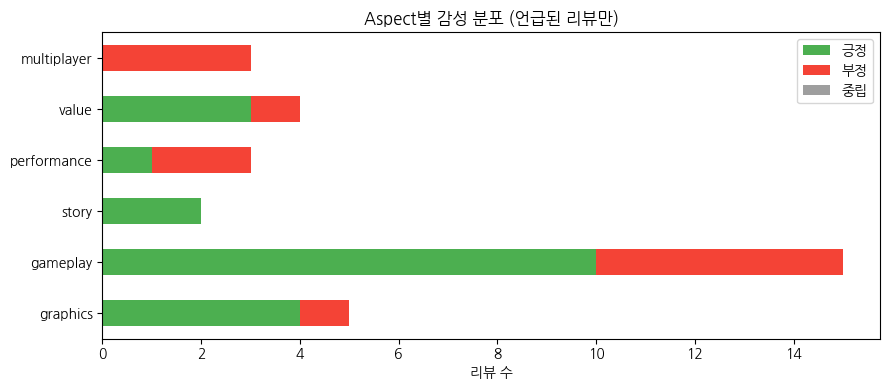

In [33]:
# Aspect별 감성 분포표 + 그래프
!pip install -q koreanize-matplotlib
import koreanize_matplotlib
import matplotlib.pyplot as plt

LABELS = {"POSITIVE": "긍정", "NEGATIVE": "부정", "NEUTRAL": "중립", "NOT_MENTIONED": "언급없음"}
aspect_table = pd.DataFrame({a: ko_df[f"aspect_{a}"].value_counts() for a in ASPECTS}).T
aspect_table = aspect_table.reindex(columns=list(LABELS), fill_value=0).fillna(0).astype(int).rename(columns=LABELS)
aspect_table["언급 수"] = aspect_table[["긍정", "부정", "중립"]].sum(axis=1)
print("=== Aspect별 감성 분포 (40건) ===")
print(aspect_table.to_string())

ax = aspect_table[["긍정", "부정", "중립"]].plot(kind="barh", stacked=True, figsize=(9, 4), color=["#4CAF50", "#f44336", "#9E9E9E"])
ax.set_title("Aspect별 감성 분포 (언급된 리뷰만)")
ax.set_xlabel("리뷰 수")
plt.tight_layout()
plt.show()

In [34]:
# 토픽별 키워드 상위 10개 (과제 안내 Step 5: 토픽별 그룹화 → 키워드 수집 → 빈도 → 상위 10)
from collections import Counter

kw_rows = pd.DataFrame([k for ks in ko_df["keywords"] for k in kw_list(ks)])
print(f"추출된 키워드: {len(kw_rows)}개 (리뷰당 평균 {len(kw_rows) / len(ko_df):.1f}개)")
print("토픽 분포:", kw_rows["topic"].value_counts().to_dict())

for topic in ["technical", "content", "value", "community", "other"]:
    words = Counter(kw_rows.loc[kw_rows["topic"] == topic, "word"].str.strip())
    print(f"\n=== 토픽: {topic} ({sum(words.values())}개) ===")
    if not words:
        print("  (해당 토픽 키워드 없음)")
    for rank, (w, c) in enumerate(words.most_common(10), 1):
        print(f"  {rank:2}. {w} {c}회")

추출된 키워드: 92개 (리뷰당 평균 2.3개)
토픽 분포: {'content': 47, 'other': 14, 'technical': 11, 'value': 10, 'community': 10}

=== 토픽: technical (11개) ===
   1. 저사양 1회
   2. 업그레이드 1회
   3. 컴퓨터 1회
   4. AI 1회
   5. 업데이트 1회
   6. 망했어요 1회
   7. 서버 1회
   8. 불안정 1회
   9. 최적화 1회
  10. 렉 1회

=== 토픽: content (47개) ===
   1. 재밌어요 3회
   2. 밸런스 2회
   3. 게임 2회
   4. 그래픽 2회
   5. 콘텐츠 2회
   6. 공정 1회
   7. 무난 1회
   8. 222시간 1회
   9. 질리지 않아요 1회
  10. 엔딩 1회

=== 토픽: value (10개) ===
   1. 시간 2회
   2. 가격 2회
   3. 382시간 1회
   4. 가성비 1회
   5. 세일 1회
   6. 리플레이 1회
   7. 알차요 1회
   8. 선물 1회

=== 토픽: community (10개) ===
   1. 스팀 라이브러리 1회
   2. 친구 1회
   3. 커뮤니티 1회
   4. 독성 1회
   5. 뉴비 1회
   6. 멀티플레이 1회
   7. 매칭 1회
   8. 사람 1회
   9. 핵 유저 1회
  10. 공정한 플레이 1회

=== 토픽: other (14개) ===
   1. 게임 1회
   2. 좋은 점 1회
   3. 아쉬운 점 1회
   4. 스크린샷 1회
   5. 강력 추천 1회
   6. 추천 1회
   7. 답답함 1회
   8. 실망 1회
   9. 기대 1회
  10. 이전 버전 1회


In [35]:
# 신뢰도 구간 분포 + 추천 여부와 감성 비교
bins = pd.cut(ko_df["confidence"], [0, 0.5, 0.8, 1.0], labels=["0.5 미만 (검토 필요)", "0.5~0.8 (참고 수준)", "0.8 이상 (신뢰 가능)"], include_lowest=True)
print("=== 신뢰도 구간 ===")
print(bins.value_counts().sort_index().to_string())
print(f"평균 신뢰도: {ko_df['confidence'].mean():.2f}")
print("\n감성별 평균 신뢰도:", ko_df.groupby("sentiment")["confidence"].mean().round(2).to_dict())

print("\n=== 추천 여부 × LLM 감성 ===")
print(pd.crosstab(ko_df["recommended"].map({True: "추천", False: "비추천"}), ko_df["sentiment"]).to_string())
clear = ko_df[ko_df["sentiment"].isin(["POSITIVE", "NEGATIVE"])]
print(f"\nPOSITIVE/NEGATIVE {len(clear)}건 중 추천 여부와 일치: {((clear['sentiment'] == 'POSITIVE') == clear['recommended']).mean() * 100:.0f}%")

low = ko_df.nsmallest(3, "confidence")[["review", "recommended", "sentiment", "confidence"]]
print("\n신뢰도가 가장 낮은 3건:")
print(low.to_string(index=False))

=== 신뢰도 구간 ===
confidence
0.5 미만 (검토 필요)      1
0.5~0.8 (참고 수준)     4
0.8 이상 (신뢰 가능)     34
평균 신뢰도: 0.89

감성별 평균 신뢰도: {'MIXED': 0.68, 'NEGATIVE': 0.91, 'PARSE_ERROR': nan, 'POSITIVE': 0.91}

=== 추천 여부 × LLM 감성 ===
sentiment    MIXED  NEGATIVE  PARSE_ERROR  POSITIVE
recommended                                        
비추천              2        13            1         0
추천               2         0            0        22

POSITIVE/NEGATIVE 35건 중 추천 여부와 일치: 100%

신뢰도가 가장 낮은 3건:
                             review  recommended sentiment  confidence
              콘텐츠 업데이트 보고 다시 평가할게요.        False     MIXED        0.25
             이 게임 하려고 컴퓨터 업그레이드했어요.         True  POSITIVE        0.70
좋은 점도 있고 아쉬운 점도 있어요. 세일 때 사면 괜찮을 듯.         True     MIXED        0.75


## 7. 결과 메모

**[적용 결과]**
- 수정 2건: API 키는 길이만 표시, 없는 파일(`reviews_clean.csv`)을 읽던 1000건 추출 셀은 파일이 있을 때만 실행
- 영어 샘플 10건(4-6, 원본 코드): POSITIVE 4 / NEGATIVE 3 / MIXED 2 / PARSE_ERROR 1, 함수 테스트도 PARSE_ERROR(쉼표가 빠진 JSON) → 원본 코드에는 재시도가 없어 그대로 둠
- 한국어 리뷰 40건(6장, 추천 24 + 비추천 16): 1차 성공 34건(85%) → **실패 건만 최대 2회 재시도해 39건 성공(98%)**, 끝까지 실패 1건
- 감성: POSITIVE 22 / NEGATIVE 13 / MIXED 4 / PARSE_ERROR 1, POSITIVE·NEGATIVE 35건은 추천 여부와 100% 일치
- 신뢰도: 0.8 이상 34건, 0.5~0.8 4건, 0.5 미만 1건, 평균 0.89 (MIXED 평균 0.68, POSITIVE·NEGATIVE 0.91)
- Aspect 언급 수: gameplay 15 > graphics 5 > value 4 > performance·multiplayer 3 > story 2
- 키워드 92개(리뷰당 2.3개), 토픽: content 47 / other 14 / technical 11 / value 10 / community 10
- 저장: `korean_unified_analysis_40.csv` (40행 × 13열: 감성·신뢰도·Aspect 6개·키워드·토픽·요약)

**[발견한 점]**
1. **통합 프롬프트는 JSON이 깨지기 쉽다**: 실패 6건 중 4건은 쉼표 누락·문자열이 닫히지 않은 JSON, 2건은 빈 응답이었다. 출력 항목이 많아 응답이 길어지면서 `max_tokens=1024` 안에서 추론과 출력이 잘리는 것으로 보인다. 재시도만으로 5건이 복구됐고, 근본적으로는 토큰 한도를 늘리거나 JSON 모드(`response_format`)를 쓰는 방법이 있다.
2. **신뢰도는 애매함을 잘 짚는다**: 신뢰도가 가장 낮은 리뷰는 '콘텐츠 업데이트 보고 다시 평가할게요'(MIXED, 0.25), '이 게임 하려고 컴퓨터 업그레이드했어요'(POSITIVE, 0.70)였다. MIXED의 평균 신뢰도(0.68)가 확실한 감성(0.91)보다 낮아 "0.8 미만은 사람이 확인" 같은 필터로 쓸 수 있다.
3. **Aspect는 대부분 '언급없음'이다**: 짧은 한국어 리뷰라 Aspect당 평균 87%가 NOT_MENTIONED였다. gameplay만 15건 언급(긍정 10·부정 5)되어 의견이 갈렸고, multiplayer는 언급 3건이 모두 부정, performance도 부정이 많아 개선 영역으로 보인다.
4. **토픽 분류가 한쪽으로 쏠린다**: 키워드의 절반(47/92)이 content였고, '게임', '재밌어요', '추천'처럼 의미가 약한 단어가 content나 other로 들어갔다. 키워드 빈도도 대부분 1~3회라, 상위 10개를 의미 있게 보려면 표본을 늘리거나 불용어를 거르는 과정이 필요하다.
5. **라벨 고정 규칙이 효과가 있었다**: 18차시처럼 라벨에 없던 값(NEUTRAL)이 전체 감성에 나오지 않았고, 키워드도 영어로 번역되지 않고 리뷰에 나온 표현('렉', '가성비', 'AI' 등) 그대로 나왔다.

---

## 정리

### 이번 시간에 만든 것

```
리뷰 1개 → 통합 분석 → 감성 + Aspect + 키워드 + 요약
                        (1번 API 호출로 끝!)
```

### 핵심 패턴

```python
# 1. 모델을 한 곳에서 관리
MODEL = "openai/gpt-oss-20b"

# 2. JSON 응답 정제 함수
def clean_json_response(response_text):
    # 마크다운 코드블록 제거, JSON 추출
    ...

# 3. LLM 호출 헬퍼 (모델 자동 지정)
def call_llm_json(system_prompt, user_message):
    raw = call_llm(system_prompt, user_message)
    return json.loads(clean_json_response(raw))
```

### 배운 점

1. **모델 중앙화**: 설정을 한 곳에서 관리하면 유지보수 편함
2. **JSON 정제**: 모델마다 응답 형식이 다를 수 있으므로 전처리 필수
3. **통합의 장점**: 1번 호출로 여러 분석 가능 → 비용 절약

### 다음 시간 예고

22차시에서는 **Retrieval 기초**를 다룹니다.